# Audit and label distributions (Part 4.1, Q1)

Parses the XML, audits the text, applies the duplicate policy, writes the clean files, then describes the labels of train, val and test.

In [1]:
import sys
sys.path.append("..")

import re

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.data import CLEAN_DATA_DIR, CLEAN_TEST_PATH, CLEAN_TRAIN_PATH, parse, split
from src.preprocessing import NORM_STEPS, build_pipeline

SEED = 42
sns.set_theme(style="whitegrid", context="notebook")

## 1. Parsing

In [2]:
df = parse()
opinions = df.dropna(subset=["category"])
sentence_table = df.drop_duplicates("sentence_id")[["split", "review_id", "sentence_id", "text"]].copy()

summary = df.groupby("split").agg(
    reviews=("review_id", "nunique"),
    sentences=("sentence_id", "nunique"),
    opinions=("category", "count"),
)
summary["no_opinion"] = df[df.category.isna()].groupby("split").size()
summary

,reviews,sentences,opinions,no_opinion
split,,,,
test,452,1227,2604,2
train,1839,4802,10509,12


The counts match the subject: 1,839 reviews and 4,802 sentences in train, 452 and 1,227 in test. Only 12 train sentences and 2 test sentences have no opinion.

## 2. Text audit: diacritics, noise and dialect

In [3]:
TEXT_PATTERNS = {
    "diacritics": r"[\u064B-\u0652]",
    "kashida": "\u0640",
    "elongation": r"(\D)\1{2,}",
    "digits": r"[0-9٠-٩]",
    "latin letters": "[A-Za-z]",
    "punctuation": r"[^\w\s\u064B-\u0652]",
}

def share_matching(texts, pattern):
    return texts.map(lambda text: bool(re.search(pattern, text))).mean()


audit = pd.DataFrame({
    name: sentence_table.groupby("split").text.apply(share_matching, pattern=pattern)
    for name, pattern in TEXT_PATTERNS.items()
})
audit.round(3)

,diacritics,kashida,elongation,digits,latin letters,punctuation
split,,,,,,
test,0.257,0.002,0.085,0.121,0.014,0.674
train,0.240,0.004,0.060,0.132,0.017,0.635


In [4]:
DIALECT_WORDS = ["مش", "مو", "بس", "كتير", "هيك", "ليش", "شو", "وايد", "مره", "زي", "دي", "كده", "عشان", "ازاي", "حلو"]


def word_pattern(words):
    return r"(?:^|\s)(?:" + "|".join(words) + r")(?:\s|$)"


dialect = pd.Series({word: share_matching(sentence_table.text, word_pattern([word])) for word in DIALECT_WORDS})
print(f"Sentences with at least one marker: {share_matching(sentence_table.text, word_pattern(DIALECT_WORDS)):.1%}")
dialect.sort_values(ascending=False).round(4)

Sentences with at least one marker: 2.6%


مش      0.0080
بس      0.0060
مره     0.0060
حلو     0.0035
كتير    0.0022
كده     0.0015
دي      0.0012
عشان    0.0012
مو      0.0010
زي      0.0007
شو      0.0003
وايد    0.0002
ليش     0.0002
ازاي    0.0002
هيك     0.0000
dtype: float64

About 1 sentence in 4 has diacritics, so they are worth normalizing for word features. Kashida is almost absent. Elongation, digits and punctuation are common enough to test by ablation (Q3). The Latin-letter share is under 2%.

The dialect check is only a lower bound, because it uses a short list of markers: 2.6% of sentences contain one, and some words are ambiguous (`مره`, `بس`). The corpus is mostly Modern Standard Arabic with some dialect.

## 3. Duplicates

In [5]:
normalize = build_pipeline(NORM_STEPS)
sentence_table["normalized"] = sentence_table.text.map(normalize)

labelled = opinions.assign(label=opinions.category + ":" + opinions.polarity)
labels_by_sentence = labelled.groupby("sentence_id").label.agg(lambda labels: " | ".join(sorted(set(labels))))
sentence_table["labels"] = sentence_table.sentence_id.map(labels_by_sentence).fillna("")

train_sentences = sentence_table[sentence_table.split == "train"]
test_sentences = sentence_table[sentence_table.split == "test"]
label_versions = train_sentences.groupby("normalized").labels.transform("nunique")

print("Exact duplicates in train:", train_sentences.text.duplicated().sum())
print("Normalized duplicates in train:", train_sentences.normalized.duplicated().sum())
print("Normalized texts with contradictory labels:", train_sentences[label_versions > 1].normalized.nunique())
print("Test sentences also in train, exact:", test_sentences.text.isin(train_sentences.text).sum())
print("Test sentences also in train, normalized:", test_sentences.normalized.isin(train_sentences.normalized).sum())

Exact duplicates in train: 14
Normalized duplicates in train: 17
Normalized texts with contradictory labels: 3
Test sentences also in train, exact: 5
Test sentences also in train, normalized: 6


**Policy**

* Train, same text and same labels: keep one copy, so a repeated sentence does not count twice.
* Train, same text and different labels: drop every copy, because we cannot tell which annotation is right.
* Test: never changed. The sentences it shares with train are only reported, so the score stays comparable with the official one.
* Sentences without opinion stay: they teach the model that no category is also possible.

In [6]:
kept_sentences = train_sentences[label_versions == 1].drop_duplicates("normalized")
clean_train = df[df.sentence_id.isin(kept_sentences.sentence_id)]
clean_test = df[df.split == "test"]

CLEAN_DATA_DIR.mkdir(parents=True, exist_ok=True)
clean_train.drop(columns="split").to_csv(CLEAN_TRAIN_PATH, index=False)
clean_test.drop(columns="split").to_csv(CLEAN_TEST_PATH, index=False)

print(f"Train sentences: {len(train_sentences)} -> {len(kept_sentences)}")

Train sentences: 4802 -> 4782


Duplicates are rare: 17 normalized duplicates and 3 contradictory texts in train. The policy removes 20 of 4,802 sentences. Test keeps its 6 sentences shared with train.

## 4. Train, val and test labels (Q1)

In [7]:
train_part, val_part = split(kept_sentences, seed=SEED)
split_of_sentence = pd.concat([
    pd.Series("train", index=train_part.sentence_id),
    pd.Series("val", index=val_part.sentence_id),
    pd.Series("test", index=test_sentences.sentence_id),
])

labelled_sentences = pd.concat([clean_train, clean_test]).assign(
    split=lambda table: table.sentence_id.map(split_of_sentence)
)
labelled_opinions = labelled_sentences.dropna(subset=["category"])
SPLIT_ORDER = ["train", "val", "test"]

labelled_sentences.groupby("split").agg(
    reviews=("review_id", "nunique"),
    sentences=("sentence_id", "nunique"),
    opinions=("category", "count"),
).loc[SPLIT_ORDER]

,reviews,sentences,opinions
split,,,
train,1654,4301,9403
val,184,481,1075
test,452,1227,2604


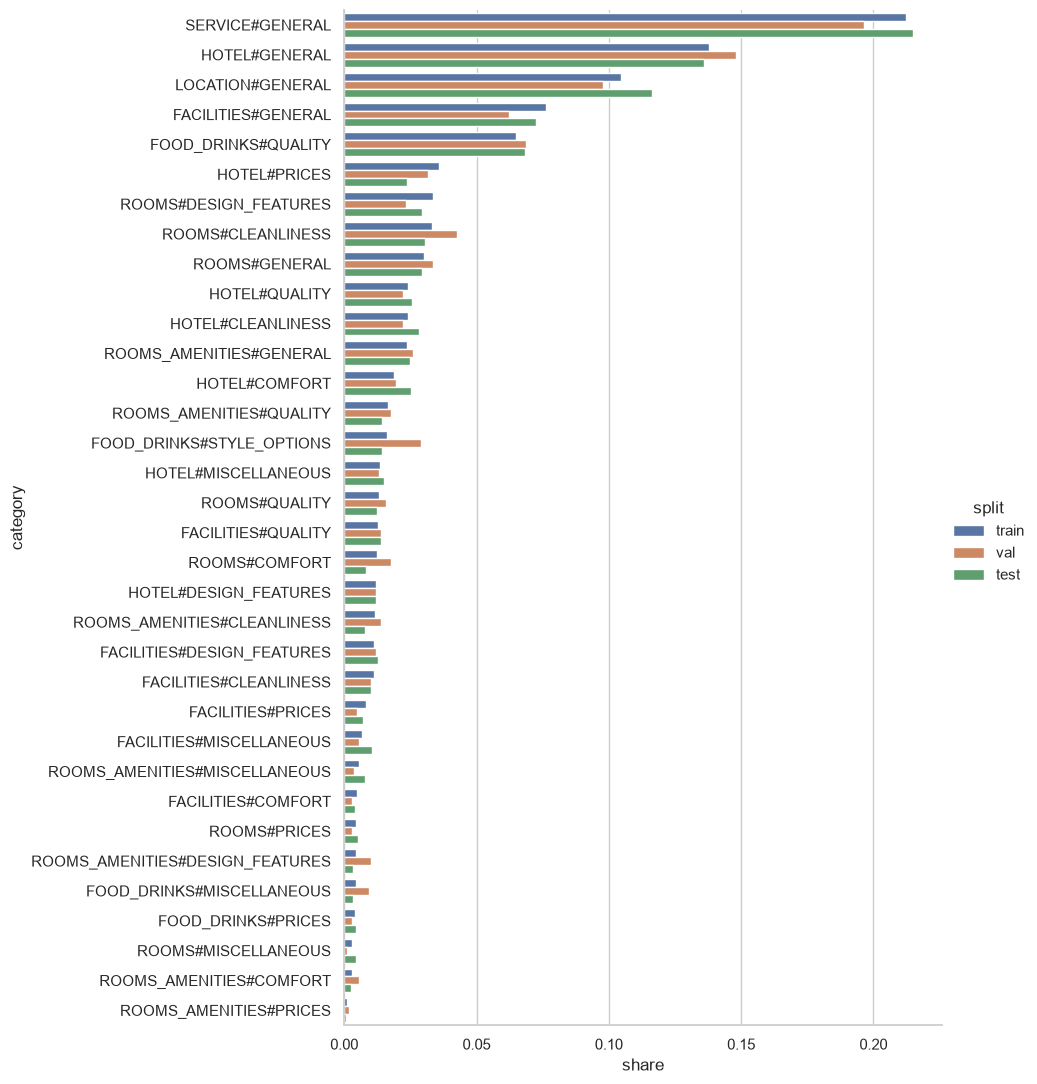

In [8]:
category_shares = (
    labelled_opinions.groupby("split").category.value_counts(normalize=True).rename("share").reset_index()
)
category_order = labelled_opinions[labelled_opinions.split == "train"].category.value_counts().index
sns.catplot(data=category_shares, y="category", x="share", hue="split", hue_order=SPLIT_ORDER,
            kind="bar", order=category_order, height=11, aspect=0.9);

In [9]:
entity_table = pd.crosstab(labelled_opinions.entity, labelled_opinions.split, normalize="columns")[SPLIT_ORDER]
entity_table.sort_values("train", ascending=False).round(3)

split,train,val,test
entity,,,
HOTEL,0.267,0.269,0.266
SERVICE,0.212,0.196,0.215
FACILITIES,0.131,0.112,0.131
ROOMS,0.130,0.137,0.120
LOCATION,0.104,0.098,0.116
FOOD_DRINKS,0.089,0.110,0.091
ROOMS_AMENITIES,0.066,0.079,0.061


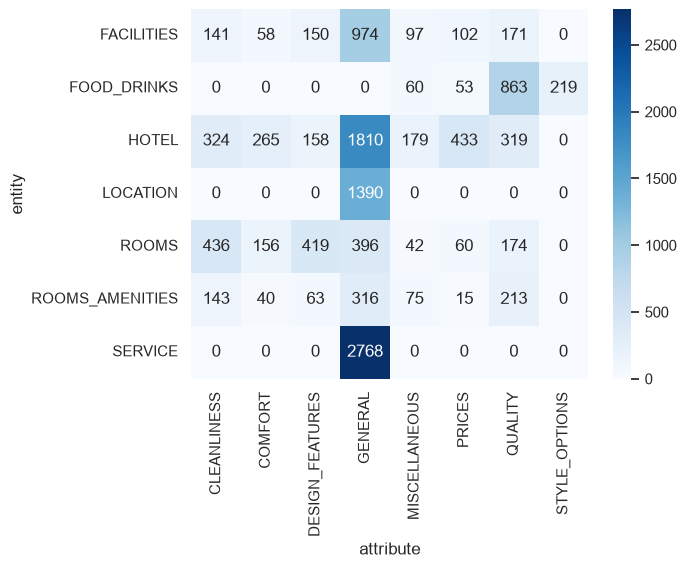

In [10]:
sns.heatmap(pd.crosstab(labelled_opinions.entity, labelled_opinions.attribute), annot=True, fmt="d", cmap="Blues");

In [11]:
train_category_counts = labelled_opinions[labelled_opinions.split == "train"].category.value_counts()
print("Share of opinions in the top 5 categories:", round(train_category_counts.head(5).sum() / train_category_counts.sum(), 3))
print("Categories with fewer than 50 train opinions:", (train_category_counts < 50).sum())
print("Categories with fewer than 20 train opinions:", (train_category_counts < 20).sum())

val_categories = labelled_opinions[labelled_opinions.split == "val"].category.value_counts()
print("Categories with fewer than 5 val opinions:", (val_categories.reindex(train_category_counts.index).fillna(0) < 5).sum())

Share of opinions in the top 5 categories: 0.596
Categories with fewer than 50 train opinions: 8
Categories with fewer than 20 train opinions: 1
Categories with fewer than 5 val opinions: 6


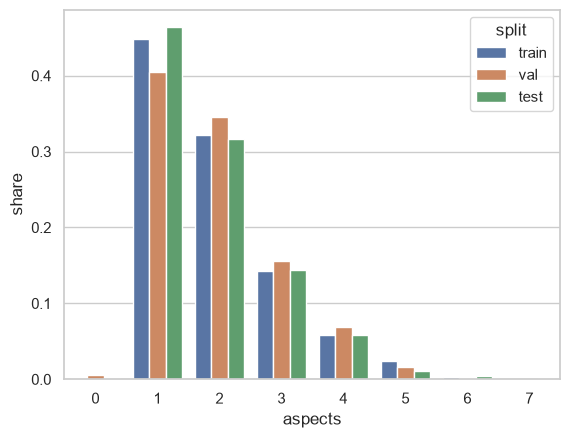

,mean,median,max
split,,,
train,1.89,2.0,7
val,1.93,2.0,6
test,1.85,2.0,7


In [12]:
aspects_per_sentence = labelled_sentences.groupby(["split", "sentence_id"]).category.nunique().rename("aspects")
aspect_shares = aspects_per_sentence.groupby("split").value_counts(normalize=True).rename("share").reset_index()
aspect_shares = aspect_shares[aspect_shares.aspects <= 8]
sns.barplot(data=aspect_shares, x="aspects", y="share", hue="split", hue_order=SPLIT_ORDER)
plt.show()

aspects_per_sentence.groupby("split").agg(["mean", "median", "max"]).loc[SPLIT_ORDER].round(2)

In [13]:
polarity_table = pd.crosstab(labelled_opinions.split, labelled_opinions.polarity, normalize="index").loc[SPLIT_ORDER]
polarity_table.round(3)

polarity,negative,neutral,positive
split,,,
train,0.343,0.066,0.591
val,0.368,0.060,0.572
test,0.356,0.065,0.579


In [14]:
polarities_by_sentence = labelled_opinions.groupby(["split", "sentence_id"]).polarity.agg(set)
is_mixed = polarities_by_sentence.map(lambda polarities: {"positive", "negative"} <= polarities)
is_mixed.groupby("split").mean().loc[SPLIT_ORDER].round(3)

split
train    0.077
val      0.090
test     0.071
Name: polarity, dtype: float64

**Conclusions (Q1)**

* Train, val and test have very close distributions by entity and by polarity, so a big prior shift is not expected.
* The label distribution has a long tail: the top 5 categories hold 60% of the opinions, and 6 categories have fewer than 5 opinions in val, too few to tune a threshold on them.
* Sentences have about 1.9 aspects on average, up to 7, so this is truly multi-label.
* `neutral` is about 6.5% of opinions, so polarity needs macro-F1, because accuracy would hide it.
* 7 to 9% of sentences mix positive and negative aspects: this is where copying one sentence polarity onto every aspect must fail.
* Micro-F1 stays the main metric for categories because it is the official one, with macro-F1 next to it to show the rare categories.

## 5. Useful for the next parts

In [15]:
print("Share of implicit aspects (target = NULL):", round((opinions.target == "NULL").mean(), 3))

pair_polarities = labelled_opinions.groupby(["sentence_id", "category"]).polarity.nunique()
print("(sentence, category) pairs:", len(pair_polarities))
print("Pairs with conflicting polarities:", (pair_polarities > 1).sum())

opinions_per_pair = labelled_opinions.groupby(["sentence_id", "category"]).size()
print("Pairs with several opinions:", (opinions_per_pair > 1).sum())

Share of implicit aspects (target = NULL): 0.085
(sentence, category) pairs: 11343
Pairs with conflicting polarities: 122
Pairs with several opinions: 1453


count    4782.0
mean       20.9
std        13.9
min         1.0
50%        18.0
95%        51.0
99%        66.0
max        84.0


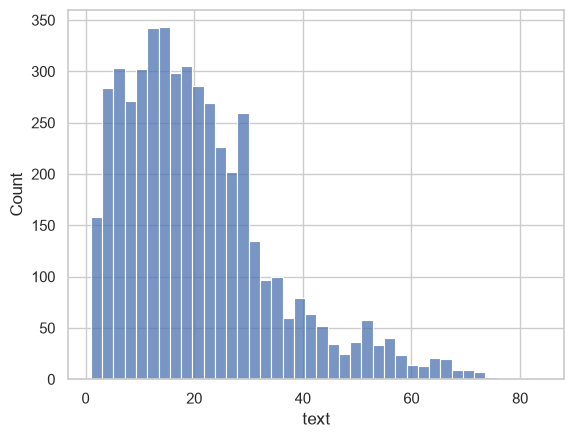

In [16]:
words_per_sentence = kept_sentences.text.str.split().str.len()
print(words_per_sentence.describe(percentiles=[0.5, 0.95, 0.99]).round(1).to_string())
sns.histplot(words_per_sentence, bins=40);

In [17]:
train_opinions = labelled_opinions[labelled_opinions.split == "train"]
examples = train_opinions.groupby("category").sample(1, random_state=0).assign(
    count=lambda table: table.category.map(train_category_counts),
    text=lambda table: table.text.str[:80],
)
examples.sort_values("count", ascending=False)[["category", "count", "polarity", "target", "text"]].reset_index(drop=True)

,category,count,polarity,target,text
0,SERVICE#GENERAL,1997,positive,فريق العمل,فريق العمل كان ودوداً.
1,HOTEL#GENERAL,1297,negative,المكان,غير نظيف بالمره الفندق سيء بكل ما تعنيه الكلمه...
2,LOCATION#GENERAL,982,positive,مكان,مكان جيد بمرافق رديئة
3,FACILITIES#GENERAL,718,positive,واحةٌ,إقامةٌ لطيفة ليلة واحدة فقط ولكننا تمنينا لو ...
4,FOOD_DRINKS#QUALITY,611,positive,الطعام,سيدة أنيقة مكثت هنا لمدة ليلتين في تشرين الثان...
5,HOTEL#PRICES,337,negative,السعر,فندق جميل ولكن الفندق رائع وكل حاجة حلوة بس فى...
6,ROOMS#DESIGN_FEATURES,317,positive,الغرف,الغرف مصممة جيدا، ونظيفة والبعض به شرفة رائعة ...
7,ROOMS#CLEANLINESS,311,positive,الغرف,أجمل الفنادق في المدينة المنورة فندق شدا المدي...
8,ROOMS#GENERAL,283,neutral,الغرفه,فندق لزوّار القرية العالمية ودبي لاند والسوق ا...
9,HOTEL#QUALITY,228,negative,فندق,فندق اقل من متوسط


**Useful for the next parts**

* 8.5% of opinions have an implicit aspect (`target = NULL`), which matters for F3.
* 122 of 11,343 (sentence, category) pairs have conflicting polarities. They are marked `ambiguous`, left out of polarity scores, and either polarity is accepted in the full pipeline.
* 99% of sentences have 66 words or fewer, a starting point for `max_len`.